# Поглощение признаков в SAE на синтетических иерархических данных

Sparse autoencoder (SAE) обучают на активациях модели, чтобы разложить их на понятные признаки. Обычно качество SAE оценивают по ошибке реконструкции и по разреженности (сколько латентов активно на пример). Но эти метрики ничего не говорят о том, совпадают ли латенты с настоящими признаками.

Одна известная проблема - feature absorption. Если признак A почти всегда встречается вместе с B (например, "собака" почти всегда идет вместе с какой-то конкретной породой), SAE может "вшить" A в латенты для B. Тогда латент "собака" перестает срабатывать в тех местах, где он нужен.

На реальной модели это сложно проверить, потому что настоящие признаки неизвестны. Поэтому делаю синтетические данные с известной иерархией, обучаю на них SAE и сравниваю латенты с правильным ответом.

План:
1. Данные: признаки-родители, признаки-дети и независимые признаки
2. SAE на numpy
3. Обычные метрики при разной силе L1
4. Сравнение с настоящими признаками
5. Одна семья признаков крупно
6. Почему так происходит
7. Зависимость от того, как часто родитель идет с ребенком

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})
rng = np.random.default_rng(0)

## 1. Данные

- N_PAR родителей, у каждого N_CH детей
- N_FLAT независимых признаков (контрольная группа без иерархии)
- каждому признаку соответствует случайный единичный вектор в R^d
- пример x = сумма векторов активных признаков

Правила:
- родитель активен с вероятностью P_PAR
- если родитель активен, то с вероятностью P_CH активен ровно один из его детей
- ребенок без родителя не бывает
- независимые признаки активны с вероятностью P_FLAT

In [2]:
N_PAR, N_CH, N_FLAT, D = 8, 4, 16, 48
P_PAR, P_CH, P_FLAT = 0.1, 0.7, 0.05

n_feat = N_PAR * (1 + N_CH) + N_FLAT
par_idx = np.arange(N_PAR)
child_idx = N_PAR + np.arange(N_PAR * N_CH).reshape(N_PAR, N_CH)
flat_idx = np.arange(N_PAR * (1 + N_CH), n_feat)

W_true = rng.normal(size=(n_feat, D))
W_true /= np.linalg.norm(W_true, axis=1, keepdims=True)


def sample(batch, rng, p_ch=P_CH):
    A = np.zeros((batch, n_feat))
    par = rng.random((batch, N_PAR)) < P_PAR
    A[:, par_idx] = par
    has_child = par & (rng.random((batch, N_PAR)) < p_ch)
    which = rng.integers(N_CH, size=(batch, N_PAR))
    b, p = np.nonzero(has_child)
    A[b, child_idx[p, which[b, p]]] = 1
    A[:, flat_idx] = rng.random((batch, N_FLAT)) < P_FLAT
    return A


A = sample(100000, rng)
print("признаков:", n_feat, " размерность:", D)
print("в среднем активных признаков на пример:", A.sum(1).mean().round(2))
print("P(ребенок | родитель) =", (A[:, child_idx].sum(2)[A[:, par_idx] == 1]).mean().round(2))
print("ребенок без родителя:", int(((A[:, child_idx].sum(2) > 0) & (A[:, par_idx] == 0)).sum()))

признаков: 56  размерность: 48
в среднем активных признаков на пример: 2.16
P(ребенок | родитель) = 0.7
ребенок без родителя: 0


Признаков (56) больше, чем размерностей (48), так что векторы не могут быть ортогональными. Это суперпозиция, как в реальных моделях.

## 2. SAE

Стандартная архитектура:

$$f = \mathrm{ReLU}(W_{enc}(x - b_{dec}) + b_{enc}), \qquad \hat x = W_{dec} f + b_{dec}$$

Лосс: $\|x - \hat x\|^2 + \lambda \|f\|_1$. Строки $W_{dec}$ после каждого шага нормирую на единицу, иначе SAE обманывает L1, уменьшая f и увеличивая $W_{dec}$.

Градиенты считаю руками, оптимизатор Adam.

In [3]:
def train_sae(lam, m=64, steps=6000, batch=1024, lr=1e-3, seed=0, p_ch=P_CH):
    r = np.random.default_rng(seed)
    We = r.normal(size=(D, m)) / np.sqrt(D)
    Wd = We.T.copy()
    Wd /= np.linalg.norm(Wd, axis=1, keepdims=True)
    be, bd = np.zeros(m), np.zeros(D)
    params = [We, be, Wd, bd]
    m1 = [np.zeros_like(p) for p in params]
    m2 = [np.zeros_like(p) for p in params]
    for t in range(1, steps + 1):
        X = sample(batch, r, p_ch) @ W_true
        pre = (X - bd) @ We + be
        f = np.maximum(pre, 0)
        gX = 2 * (f @ Wd + bd - X) / batch
        gpre = (gX @ Wd.T + lam * (f > 0) / batch) * (pre > 0)
        grads = [
            (X - bd).T @ gpre,
            gpre.sum(0),
            f.T @ gX,
            gX.sum(0) - (gpre @ We.T).sum(0),
        ]
        for i, (p, g) in enumerate(zip(params, grads)):
            m1[i] = 0.9 * m1[i] + 0.1 * g
            m2[i] = 0.999 * m2[i] + 0.001 * g * g
            p -= lr * (m1[i] / (1 - 0.9**t)) / (np.sqrt(m2[i] / (1 - 0.999**t)) + 1e-8)
        Wd /= np.linalg.norm(Wd, axis=1, keepdims=True)
    return We, be, Wd, bd


def encode(X, sae):
    We, be, Wd, bd = sae
    return np.maximum((X - bd) @ We + be, 0)


def decode(F, sae):
    return F @ sae[2] + sae[3]

## 3. Обычные метрики

Обучаю SAE при разных λ и смотрю то, что обычно смотрят: ошибку реконструкции и L0 (среднее число активных латентов). Для сравнения: настоящее среднее число активных признаков около 2.2.

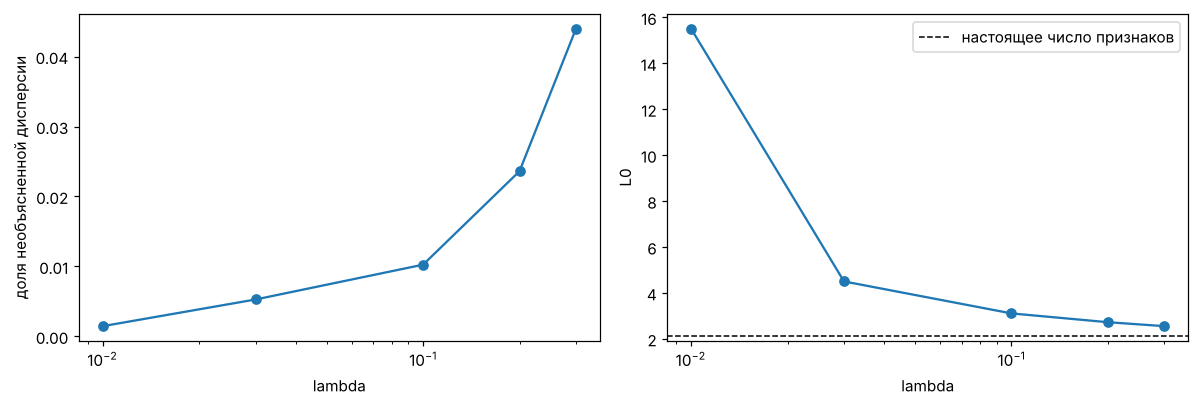

lambda = 0.01: необъясненная дисперсия 0.001, L0 = 15.51
lambda = 0.03: необъясненная дисперсия 0.005, L0 = 4.50
lambda = 0.1: необъясненная дисперсия 0.010, L0 = 3.11
lambda = 0.2: необъясненная дисперсия 0.024, L0 = 2.73
lambda = 0.3: необъясненная дисперсия 0.044, L0 = 2.55


In [4]:
LAMS = [0.01, 0.03, 0.1, 0.2, 0.3]
saes = {lam: train_sae(lam) for lam in LAMS}

A_test = sample(20000, np.random.default_rng(123))
X_test = A_test @ W_true

mse, l0 = [], []
for lam in LAMS:
    F = encode(X_test, saes[lam])
    mse.append(((decode(F, saes[lam]) - X_test) ** 2).sum(1).mean() / (X_test**2).sum(1).mean())
    l0.append((F > 0).sum(1).mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(LAMS, mse, "o-")
ax[0].set_xscale("log")
ax[0].set_xlabel("lambda")
ax[0].set_ylabel("доля необъясненной дисперсии")
ax[1].plot(LAMS, l0, "o-")
ax[1].axhline(A_test.sum(1).mean(), color="k", ls="--", lw=1, label="настоящее число признаков")
ax[1].set_xscale("log")
ax[1].set_xlabel("lambda")
ax[1].set_ylabel("L0")
ax[1].legend()
plt.tight_layout()
plt.show()

for lam, a, b in zip(LAMS, mse, l0):
    print(f"lambda = {lam}: необъясненная дисперсия {a:.3f}, L0 = {b:.2f}")

При λ = 0.1-0.2 все выглядит хорошо: реконструкция почти идеальная, L0 близко к настоящему. По этим метрикам такой SAE можно было бы считать удачным.

## 4. Сравнение с настоящими признаками

Для каждого настоящего признака беру латент, у которого вектор декодера ближе всего к нему (по косинусу). Потом смотрю:

- насколько близко (косинус) для родителей, детей и независимых признаков
- как часто латент родителя срабатывает, когда родитель активен один, и когда родитель активен вместе с ребенком

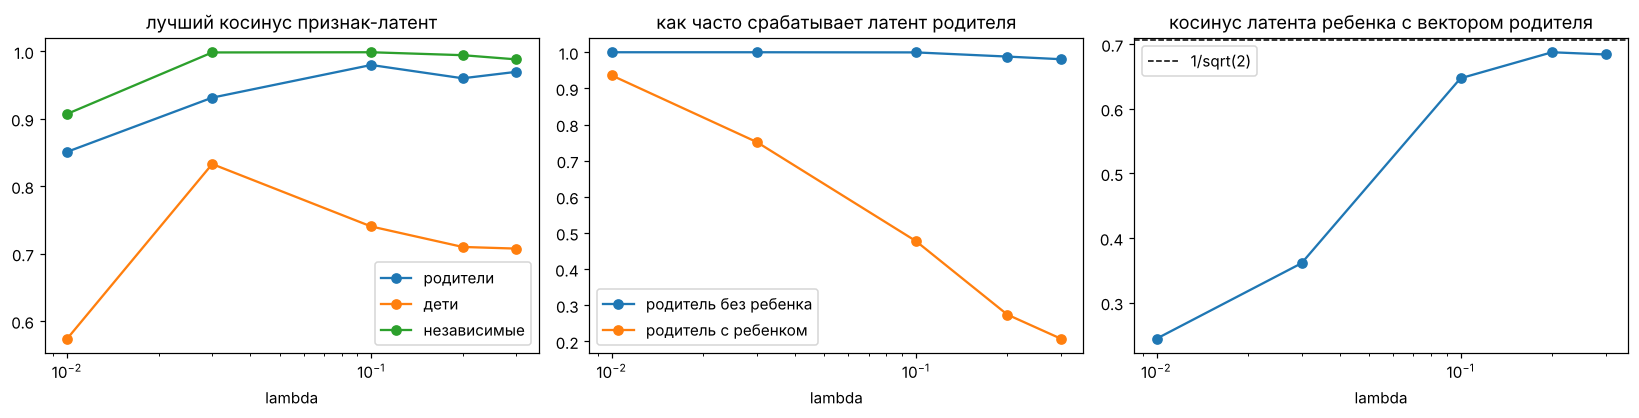

lambda = 0.01: латент родителя срабатывает 1.00 (один) / 0.94 (с ребенком)
lambda = 0.03: латент родителя срабатывает 1.00 (один) / 0.75 (с ребенком)
lambda = 0.1: латент родителя срабатывает 1.00 (один) / 0.48 (с ребенком)
lambda = 0.2: латент родителя срабатывает 0.99 (один) / 0.27 (с ребенком)
lambda = 0.3: латент родителя срабатывает 0.98 (один) / 0.21 (с ребенком)


In [5]:
def analyze(sae, A, X):
    F = encode(X, sae)
    cos = W_true @ sae[2].T
    best = cos.argmax(1)
    res = {
        "cos_par": cos.max(1)[par_idx].mean(),
        "cos_child": cos.max(1)[child_idx].mean(),
        "cos_flat": cos.max(1)[flat_idx].mean(),
    }
    alone, with_child, child_to_par = [], [], []
    for p in range(N_PAR):
        lat = best[p]
        kid = A[:, child_idx[p]].sum(1) > 0
        on = A[:, p] == 1
        alone.append((F[on & ~kid, lat] > 0).mean())
        with_child.append((F[on & kid, lat] > 0).mean())
        for c in child_idx[p]:
            child_to_par.append(cos[p, best[c]])
    res["fire_alone"] = np.mean(alone)
    res["fire_with_child"] = np.mean(with_child)
    res["child_lat_vs_par"] = np.mean(child_to_par)
    return res


results = [analyze(saes[lam], A_test, X_test) for lam in LAMS]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for key, name in [("cos_par", "родители"), ("cos_child", "дети"), ("cos_flat", "независимые")]:
    ax[0].plot(LAMS, [r[key] for r in results], "o-", label=name)
ax[0].set_title("лучший косинус признак-латент")
ax[0].legend()

ax[1].plot(LAMS, [r["fire_alone"] for r in results], "o-", label="родитель без ребенка")
ax[1].plot(LAMS, [r["fire_with_child"] for r in results], "o-", label="родитель с ребенком")
ax[1].set_title("как часто срабатывает латент родителя")
ax[1].legend()

ax[2].plot(LAMS, [r["child_lat_vs_par"] for r in results], "o-")
ax[2].axhline(1 / np.sqrt(2), color="k", ls="--", lw=1, label="1/sqrt(2)")
ax[2].set_title("косинус латента ребенка с вектором родителя")
ax[2].legend()

for a in ax:
    a.set_xscale("log")
    a.set_xlabel("lambda")
plt.tight_layout()
plt.show()

for lam, r in zip(LAMS, results):
    print(f"lambda = {lam}: латент родителя срабатывает {r['fire_alone']:.2f} (один) / {r['fire_with_child']:.2f} (с ребенком)")

Что видно:
- При λ = 0.01 SAE почти не разреженный (L0 около 15), поэтому все признаки находятся плохо. Это просто слишком слабый штраф.
- Независимые признаки при нормальных λ SAE находит почти идеально.
- Вектор родителя тоже находится хорошо (косинус высокий). То есть если смотреть только на декодер, кажется, что все в порядке.
- Но с ростом λ латент родителя перестает срабатывать, когда рядом есть ребенок. При λ = 0.2-0.3 он срабатывает только в 20-30% таких случаев.
- Латенты детей поворачиваются к вектору родителя, косинус доходит почти до 1/sqrt(2). Из-за этого и косинус латента ребенка с самим ребенком падает примерно до 0.7. Это значит, что латент ребенка стал примерно (родитель + ребенок)/sqrt(2): родитель "поглощен" ребенком.

Если бы мы интерпретировали такой SAE, мы бы решили, что латент "собака" срабатывает только на собак неизвестной породы, а для такс у нас отдельный латент, который про собак "не знает".

## 5. Одна семья крупно

Косинусы между настоящими признаками одной семьи (родитель + 4 ребенка) и их лучшими латентами, при маленьком и большом λ.

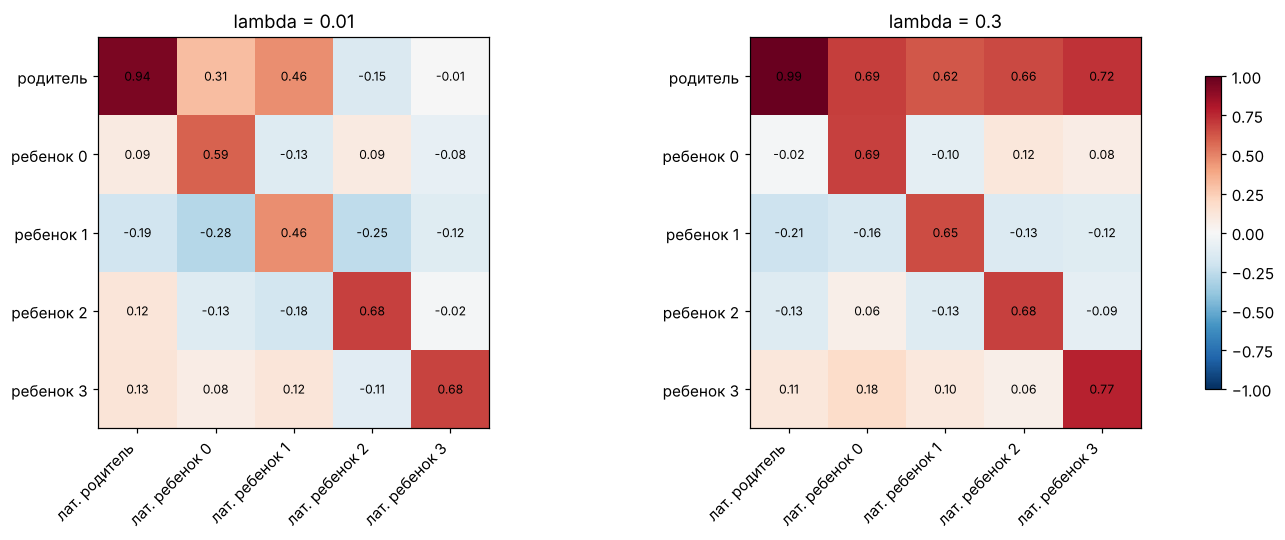

In [6]:
fam = 0
feats = [par_idx[fam]] + list(child_idx[fam])
names = ["родитель"] + [f"ребенок {i}" for i in range(N_CH)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
for a, lam in zip(ax, [LAMS[0], LAMS[-1]]):
    cos = W_true @ saes[lam][2].T
    lats = [cos[f].argmax() for f in feats]
    M = cos[np.ix_(feats, lats)]
    im = a.imshow(M, vmin=-1, vmax=1, cmap="RdBu_r")
    for i in range(len(feats)):
        for j in range(len(feats)):
            a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8)
    a.set_yticks(range(len(feats)), names)
    a.set_xticks(range(len(feats)), [f"лат. {n}" for n in names], rotation=45, ha="right")
    a.set_title(f"lambda = {lam}")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

При большом λ в первой строке (вектор родителя) у латентов детей появляются заметные косинусы, примерно 0.6-0.7. Каждый латент ребенка содержит в себе направление родителя.

## 6. Почему так происходит

Простая оценка. Пусть активны родитель и ребенок, x = p + c, векторы почти ортогональны и единичной длины.

- Вариант "честный": два латента с коэффициентами 1 и 1. L1 = 2.
- Вариант "поглощение": один латент с вектором (p + c)/|p + c|. Чтобы восстановить x, коэффициент должен быть |p + c| = sqrt(2). L1 = sqrt(2) = 1.41.

Реконструкция одинаковая, а L1 меньше. Поэтому чем сильнее штраф λ, тем выгоднее поглощение. Вектор такого латента (p + c)/sqrt(2) имеет косинус 1/sqrt(2) и с p, и с c, ровно это и видно на графиках.

Латент родителя при этом все равно нужен для случаев "родитель без ребенка", поэтому вектор родителя в декодере остается, просто срабатывает он реже.

In [7]:
p, c = W_true[par_idx[0]], W_true[child_idx[0, 0]]
x = p + c
v = x / np.linalg.norm(x)
print("косинус между p и c:", round(float(p @ c), 3))
print("L1 при двух латентах:", 2.0)
print("L1 при одном латенте:", round(float(np.linalg.norm(x)), 3))
print("косинус (p+c)/|p+c| с p:", round(float(v @ p), 3))

косинус между p и c: -0.033
L1 при двух латентах: 2.0
L1 при одном латенте: 1.391
косинус (p+c)/|p+c| с p: 0.695


## 7. Зависимость от P(ребенок | родитель)

Если родитель почти всегда идет с ребенком, поглощение выгоднее. Если редко, то латент родителя нужен сам по себе. Фиксирую λ = 0.1 и меняю P_CH.

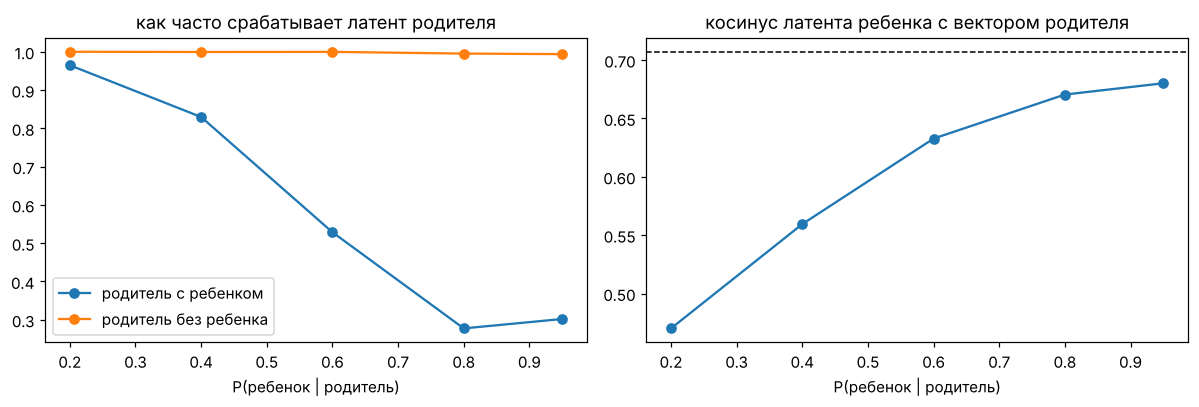

P_CH = 0.2: с ребенком 0.96, косинус 0.47
P_CH = 0.4: с ребенком 0.83, косинус 0.56
P_CH = 0.6: с ребенком 0.53, косинус 0.63
P_CH = 0.8: с ребенком 0.28, косинус 0.67
P_CH = 0.95: с ребенком 0.30, косинус 0.68


In [8]:
P_CHS = [0.2, 0.4, 0.6, 0.8, 0.95]
lam_fixed = 0.1
abs_res = []
for pc in P_CHS:
    sae = train_sae(lam_fixed, p_ch=pc)
    A_pc = sample(20000, np.random.default_rng(7), p_ch=pc)
    abs_res.append(analyze(sae, A_pc, A_pc @ W_true))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(P_CHS, [r["fire_with_child"] for r in abs_res], "o-", label="родитель с ребенком")
ax[0].plot(P_CHS, [r["fire_alone"] for r in abs_res], "o-", label="родитель без ребенка")
ax[0].set_xlabel("P(ребенок | родитель)")
ax[0].set_title("как часто срабатывает латент родителя")
ax[0].legend()
ax[1].plot(P_CHS, [r["child_lat_vs_par"] for r in abs_res], "o-")
ax[1].axhline(1 / np.sqrt(2), color="k", ls="--", lw=1)
ax[1].set_xlabel("P(ребенок | родитель)")
ax[1].set_title("косинус латента ребенка с вектором родителя")
plt.tight_layout()
plt.show()

for pc, r in zip(P_CHS, abs_res):
    print(f"P_CH = {pc}: с ребенком {r['fire_with_child']:.2f}, косинус {r['child_lat_vs_par']:.2f}")

## Итог

- На данных с иерархией SAE может выглядеть отлично по обычным метрикам (реконструкция, L0) и при этом неправильно представлять признаки-родители.
- Поглощение растет с λ и с тем, насколько часто родитель встречается вместе с ребенком.
- Без данных с известными признаками это не заметить: вектор родителя в декодере есть, и его легко принять за нормальный латент.

## Дальше

1. Проверить варианты SAE, которые должны с этим бороться (например, Matryoshka SAE, TopK SAE).
2. Сделать иерархию глубже (3-4 уровня) и посмотреть, накапливается ли поглощение по уровням.
3. Сделать разные амплитуды признаков, а не только 0/1.
4. Взять данные с более реалистичной иерархией, например из критической перколяции, где размеры кластеров распределены по степенному закону.